In [1]:
# Step 1: Data Loading

In [2]:
import pandas as pd

df = pd.read_csv(r'C:\Capstone\local-dropshipping-ai-system\ai-engine\Sales_History.csv')
print(df.head())

   order_date         sku  quantity_sold platform
0  2025-05-21  ACC-SR-007              5   TikTok
1  2025-05-21  ACC-SR-007              8   TikTok
2  2025-05-21  CLO-KP-006              5   Shopee
3  2025-05-22  HIJ-TS-005              9   Shopee
4  2025-05-22  CLO-KS-003              4   Shopee


In [3]:
import matplotlib.pyplot as plt

# 2. Change date format
df['order_date'] = pd.to_datetime(df['order_date'])

# 3. View data
print("Data is ready!")
df.head()


Data is ready!


,order_date,sku,quantity_sold,platform
0,2025-05-21,ACC-SR-007,5,TikTok
1,2025-05-21,ACC-SR-007,8,TikTok
2,2025-05-21,CLO-KP-006,5,Shopee
3,2025-05-22,HIJ-TS-005,9,Shopee
4,2025-05-22,CLO-KS-003,4,Shopee


In [4]:
import matplotlib.pyplot as plt

# 2. Change date format
df['order_date'] = pd.to_datetime(df['order_date'])

# 3. View data
print("Data is ready!")
df.head()


Data is ready!


,order_date,sku,quantity_sold,platform
0,2025-05-21,ACC-SR-007,5,TikTok
1,2025-05-21,ACC-SR-007,8,TikTok
2,2025-05-21,CLO-KP-006,5,Shopee
3,2025-05-22,HIJ-TS-005,9,Shopee
4,2025-05-22,CLO-KS-003,4,Shopee


In [5]:
# Step 2: Visualization & Trends

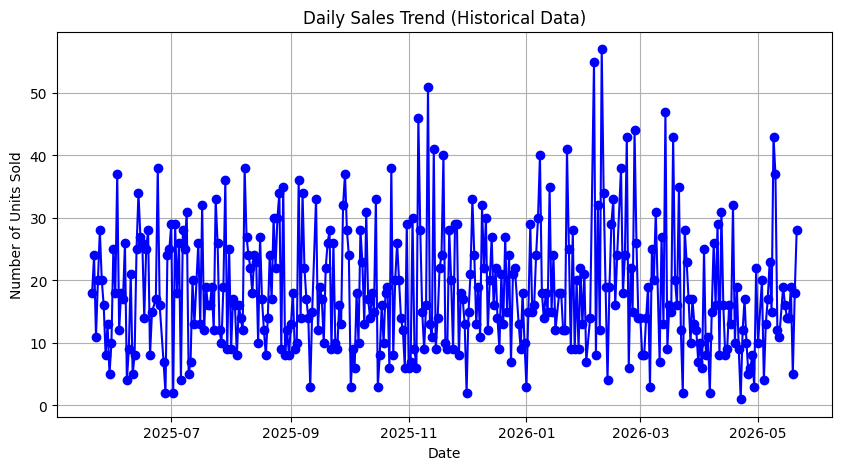

In [6]:
# # 1. Collect sales by date (Total daily sales)
# Change 'Quantity' to 'quantity_sold' according to the new CSV format
daily_sales = df.groupby('order_date')['quantity_sold'].sum().reset_index()

# # 2. Plot graphs to see trends
plt.figure(figsize=(10, 5))
# Change the Y axis to 'quantity_sold' as well
plt.plot(daily_sales['order_date'], daily_sales['quantity_sold'], marker='o', linestyle='-', color='b')
plt.title('Daily Sales Trend (Historical Data)')
plt.xlabel('Date')
plt.ylabel('Number of Units Sold')
plt.grid(True)
plt.show()

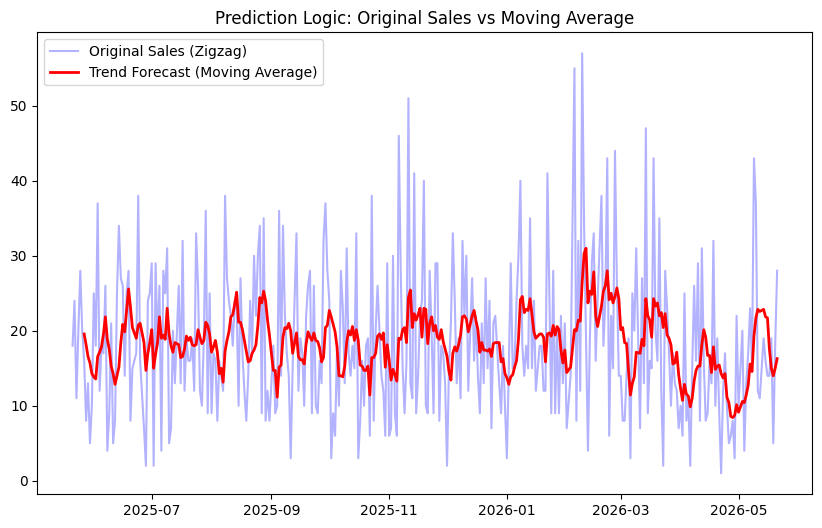

In [7]:
# 1.Calculate the moving average for 7 days (7-day Moving Average)
# Change 'Quantity' to 'quantity_sold'
daily_sales['7day_MA'] = daily_sales['quantity_sold'].rolling(window=7).mean()

# # 2. Plot the original graph vs. Average Prediction
plt.figure(figsize=(10, 6))
# Change 'Order_Date' -> 'order_date' & 'Quantity' -> 'quantity_sold'
plt.plot(daily_sales['order_date'], daily_sales['quantity_sold'], label='Original Sales (Zigzag)', alpha=0.3, color='blue')
plt.plot(daily_sales['order_date'], daily_sales['7day_MA'], label='Trend Forecast (Moving Average)', color='red', linewidth=2)

plt.title('Prediction Logic: Original Sales vs Moving Average')
plt.legend()
plt.show()

In [8]:
#Step 3: Forecasting Logic

Average sales forecast for the next 30 days: 17.81 units per day


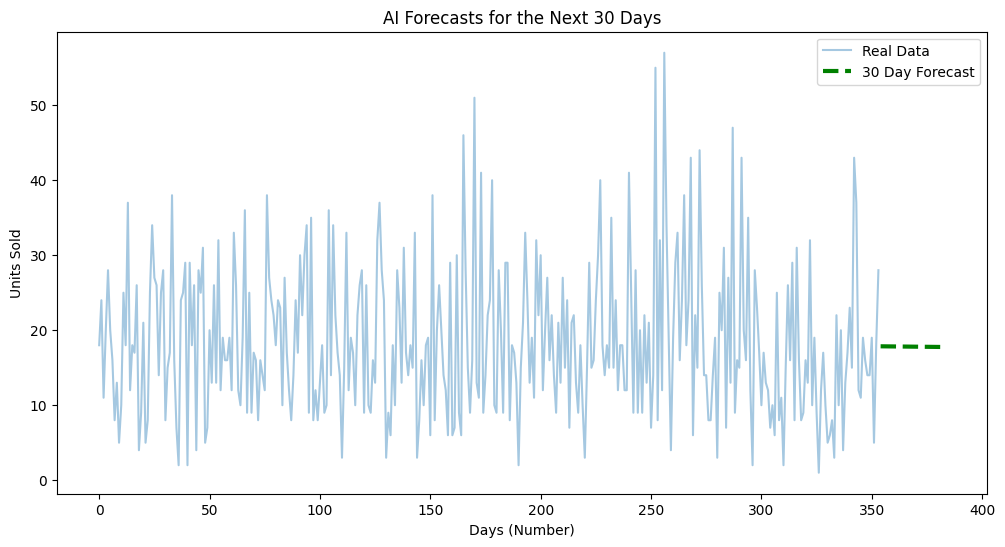

In [9]:
from sklearn.linear_model import LinearRegression
import numpy as np

# # 1. Provide data for AI to learn (Convert dates to numbers)
daily_sales['Day_Num'] = np.arange(len(daily_sales))
X = daily_sales[['Day_Num']].values # Input: What day
y = daily_sales['quantity_sold'].values # Output: change 'Quantity' -> 'quantity_sold'

# # 2. Teach AI (Training)
model = LinearRegression()
model.fit(X, y)

# # 3. Forecast 30 days ahead
future_days = np.arange(len(daily_sales), len(daily_sales) + 30).reshape(-1, 1)
future_predict = model.predict(future_days)

# # 4. Show prediction results
print(f"Average sales forecast for the next 30 days: {future_predict.mean():.2f} units per day")

# # 5. Plot the prediction graph
plt.figure(figsize=(12, 6))
plt.plot(daily_sales['Day_Num'], y, label='Real Data', alpha=0.4)
plt.plot(future_days, future_predict, label='30 Day Forecast', color='green', linestyle='--', linewidth=3)
plt.title('AI Forecasts for the Next 30 Days')
plt.xlabel('Days (Number)')
plt.ylabel('Units Sold')
plt.legend()
plt.show()

In [10]:
#Step 4: Top Seller Analysis (Sales Velocity)

In [11]:
# --- TOP SELLER & VELOCITY ANALYSIS (SKU VERSION) ---
# Change groupby to 'sku' and quantity to 'quantity_sold' according to the new file structure
product_velocity = (df.groupby('sku')['quantity_sold'].sum() / df['order_date'].nunique()).round(2)
product_velocity = product_velocity.reset_index().rename(columns={'quantity_sold': 'Avg_Daily_Sales'})

# Arrange from best seller
product_velocity = product_velocity.sort_values(by='Avg_Daily_Sales', ascending=False)

print("--- ANALISIS TOP SELLER & VELOCITY (VERSION SKU) ---")
print(product_velocity)

--- ANALISIS TOP SELLER & VELOCITY (VERSION SKU) ---
          sku  Avg_Daily_Sales
2  CLO-BM-001             3.28
4  CLO-KS-003             3.01
5  HIJ-TB-004             2.83
6  HIJ-TS-005             2.43
1  CLO-BK-002             2.38
0  ACC-SR-007             2.29
3  CLO-KP-006             2.19


In [12]:
# Step 5: Predictive Alerting

In [13]:
# 1. 'Example Stock' (Customize the list by Master SKU)
inventory_data = {
    'sku': [
        'CLO-BK-002', 'CLO-BM-001', 'CLO-KP-006', 
        'HIJ-TB-004', 'ACC-SR-007', 'HIJ-TS-005', 'CLO-KS-003'
    ],
    'Current_Stock': [50, 40, 15, 10, 100, 25, 5]
}

inventory_df = pd.DataFrame(inventory_data)

# # 2. COMBINE the sample stock data with the sales data from the dataset
# Change on='Product_Name' to on='sku'
alert_system = pd.merge(product_velocity, inventory_df, on='sku')

# # 3. LOGICAL CALCULATION: Days_Remaining = Current_Stock / Avg_Daily_Sales
alert_system['Days_Until_Stockout'] = alert_system['Current_Stock'] / alert_system['Avg_Daily_Sales']
alert_system = alert_system.round(2)

# # 4. DISPLAY RESULTS (Predictive Alerting)
print("--- STOCK WARNING SYSTEM (PREDICTIVE ALERTING) ---")
# Change the display of the 'Product_Name' column to 'sku'
print(alert_system[['sku', 'Avg_Daily_Sales', 'Current_Stock', 'Days_Until_Stockout']])

--- STOCK WARNING SYSTEM (PREDICTIVE ALERTING) ---
          sku  Avg_Daily_Sales  Current_Stock  Days_Until_Stockout
0  CLO-BM-001             3.28             40                12.20
1  CLO-KS-003             3.01              5                 1.66
2  HIJ-TB-004             2.83             10                 3.53
3  HIJ-TS-005             2.43             25                10.29
4  CLO-BK-002             2.38             50                21.01
5  ACC-SR-007             2.29            100                43.67
6  CLO-KP-006             2.19             15                 6.85
